# 08. H2, error rates by age and gender, Holm across H1 + H2 (action items C2, C4, G5, H2)

Track 4. Reads Track 3's out-of-fold (OOF) predictions `p_mi` from `data/interim/oof_final.csv` (written by `06_model.ipynb`) and H1's p-value from `results/tables/hyp_h1.csv` (written by `05_hypothesis_tests.ipynb`), so it runs after both.

Everything here was registered in `docs/hypotheses.md` on 2026-11-11 (commit 45377fa); the cost ratio R = 20 (p\* = 4.8%) was fixed on 2026-11-12 (action item A1, `docs/cost_ratio.md`) before this notebook was run.

**Words used below**
- **p\*** (p-star): the referral threshold. Refer a patient when their predicted stroke risk is at least p\* = 1 / (1 + R).
- **Net benefit (NB)**: strokes caught minus unnecessary referrals, with each unnecessary referral counting as 1/R of a stroke. Shown per 1,000 patients, it reads as *net strokes caught per 1,000 patients*.
- **Refer all / refer none**: the two strategies that need no model. The better of the two at p\* is the **best default**.
- **FN rate** (false-negative rate): share of stroke patients the model does *not* refer. **FP rate**: share of non-stroke patients it *does* refer. **PPV** (positive predictive value): share of referred patients who had a stroke.

**How to read the intervals.** A 95% interval comes from a procedure that captures the true value in about 95% of repeated samples. It is not a 95% probability statement about this particular interval.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.stats.multitest import multipletests

from src.config import ALPHA, COST_RATIO, COST_RATIO_GRID, DATA_INTERIM, FIGURES, N_BOOT, SEED, TABLES
from src.hypotheses import error_rate_table, h2_test, p_star

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

oof = pd.read_csv(DATA_INTERIM / "oof_final.csv")
assert oof["p_mi"].notna().all()
PT = p_star(COST_RATIO)
print(f"n = {len(oof):,}, strokes = {oof['stroke'].sum()}, R = {COST_RATIO}, p* = {PT:.4f}, B = {N_BOOT:,}, seed = {SEED}")

n = 5,109, strokes = 249, R = 20, p* = 0.0476, B = 10,000, seed = 42


## H2: Does the referral model beat the best default strategy?

- **H₀:** NB(model) − NB(best default) ≤ 0 at p\*. **H₁:** the difference is > 0.
- **Test:** paired bootstrap, 10,000 resamples of patients (stratified by stroke) with the OOF predictions held fixed; one-sided p = share of resamples with difference ≤ 0.
- **Effect size:** the difference in net strokes caught per 1,000 patients, with a 95% bootstrap CI.
- Repeated at every R in `COST_RATIO_GRID` (registered sensitivity analysis).

In [2]:
h2_full = h2_test(oof["stroke"], oof["p_mi"], COST_RATIO_GRID)
h2_full.insert(0, "data", "full data")

# G5 (registered sensitivity): the adult rows (age >= 18) of the same predictions
adult = oof[oof["age"] >= 18].reset_index(drop=True)
h2_adult = h2_test(adult["stroke"], adult["p_mi"], COST_RATIO_GRID)
h2_adult.insert(0, "data", "G5: adults only (age >= 18)")

h2 = pd.concat([h2_full, h2_adult], ignore_index=True)
h2.to_csv(TABLES / "hyp_h2.csv", index=False)
show = ["data", "R", "p_star", "n", "events", "best_default", "nb_model", "nb_refer_all",
        "diff_per_1000", "per_1000_low", "per_1000_high", "n_boot_le_0", "p_one_sided"]
display(h2[show].round(4))

,data,R,p_star,n,events,best_default,nb_model,nb_refer_all,diff_per_1000,per_1000_low,per_1000_high,n_boot_le_0,p_one_sided
0,full data,5,0.1667,5109,249,refer none,0.0028,-0.1415,2.8186,-0.2740,5.9111,402,0.0402
1,full data,10,0.0909,5109,249,refer none,0.0165,-0.0464,16.4611,13.3881,19.5537,0,0.0000
2,full data,20,0.0476,5109,249,refer all,0.0256,0.0012,24.4177,21.8634,26.8937,0,0.0000
3,full data,50,0.0196,5109,249,refer all,0.0365,0.0297,6.8272,5.1830,8.3108,0,0.0000
4,full data,100,0.0099,5109,249,refer all,0.0421,0.0392,2.8538,1.9162,3.6289,0,0.0000
5,G5: adults only (age >= 18),5,0.1667,4253,247,refer none,0.0034,-0.1303,3.3858,-0.2822,7.1479,363,0.0363
6,G5: adults only (age >= 18),10,0.0909,4253,247,refer none,0.0198,-0.0361,19.7743,16.1768,23.3717,0,0.0000
7,G5: adults only (age >= 18),20,0.0476,4253,247,refer all,0.0307,0.0110,19.7625,16.7526,22.6546,0,0.0000
8,G5: adults only (age >= 18),50,0.0196,4253,247,refer all,0.0439,0.0392,4.6555,2.8074,6.3438,0,0.0000
9,G5: adults only (age >= 18),100,0.0099,4253,247,refer all,0.0505,0.0487,1.8904,0.9663,2.5911,2,0.0002


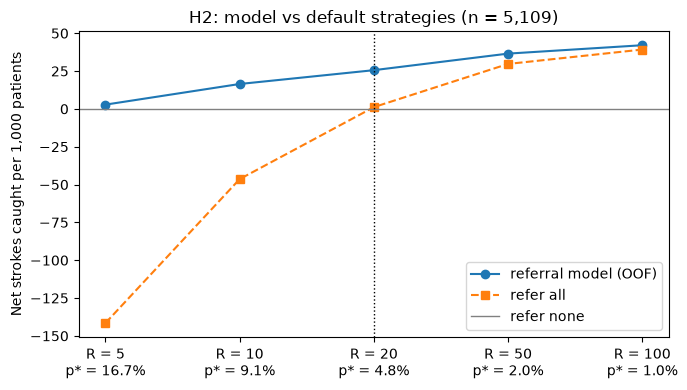

In [3]:
# Net strokes caught per 1,000 patients at each R: model vs the two defaults (full data)
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(COST_RATIO_GRID))
ax.plot(x, 1000 * h2_full["nb_model"], "o-", label="referral model (OOF)")
ax.plot(x, 1000 * h2_full["nb_refer_all"], "s--", label="refer all")
ax.axhline(0, color="grey", lw=1, label="refer none")
ax.set_xticks(x, [f"R = {r}\np* = {100 * p_star(r):.1f}%" for r in COST_RATIO_GRID])
ax.set_ylabel("Net strokes caught per 1,000 patients")
ax.set_title("H2: model vs default strategies (n = 5,109)")
ax.axvline(COST_RATIO_GRID.index(COST_RATIO), color="k", ls=":", lw=1)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "hyp_h2_net_benefit.png", bbox_inches="tight")
plt.show()

**H2 result.** At R = 20 (p\* = 4.8%) the best default is *refer all*, and only just: its net benefit is +1.2 net strokes caught per 1,000 patients, because p\* sits just below the stroke rate (4.87%). The referral model gives +25.6 per 1,000. Difference: **+24.4 net strokes caught per 1,000 patients (95% paired bootstrap CI 21.9 to 26.9)**; none of the 10,000 resamples gave a difference ≤ 0, so one-sided p < 0.0001. H₀ is rejected.

In plain numbers per 1,000 patients: the model refers 302 and catches 38.8 of the 48.7 future strokes; refer-all refers all 1,000 and catches all 48.7. The model gives up about 10 strokes to avoid about 700 unnecessary referrals, and at R = 20 (one stroke is worth 20 unnecessary referrals) that trade is clearly worth it.

**Over the grid (registered sensitivity).** The model beats the best default at R = 10, 20, 50 and 100 (all CIs above 0, p < 0.0001). At R = 5 (p\* = 16.7%, best default refer none) the gain is small: +2.8 per 1,000 (−0.3 to 5.9), one-sided p = 0.04. The one-sided p and the two-sided 95% CI answer slightly different questions, so at R = 5 we call the evidence weak. The model is useful across the plausible range of R; it is least useful when an unnecessary referral is judged expensive.

**G5 adults only (registered sensitivity).** Same conclusion: +19.8 per 1,000 (16.8 to 22.7) at R = 20, and the same pattern across R. The gain is smaller because refer-all does better among adults (higher stroke rate, 5.8%).

**Stated limitation (registered).** The predictions are held fixed, so these CIs leave out the variability from fitting the model; they are somewhat too narrow. Track 5's whole-pipeline bootstrap (A4) covers that. Given how far the CI is from 0 at R = 20, this is unlikely to change the conclusion.

## C4: Holm correction across the main family (H1, H2)

H1's p-value is from its likelihood-ratio test (does not depend on R; `05_hypothesis_tests.ipynb`). H2's is from the bootstrap at the chosen R = 20. When no resample out of B gives a difference ≤ 0, the bootstrap can only say p < 1/B, so we enter p = 1/B into the Holm step (a conservative choice).

In [4]:
h1 = pd.read_csv(TABLES / "hyp_h1.csv")
h1_p = float(h1.loc[h1["analysis"] == "H1 main: full data", "p_value"].iloc[0])
h2_main = h2_full.loc[h2_full["R"] == COST_RATIO].iloc[0]
h2_p = max(h2_main["n_boot_le_0"], 1) / h2_main["B"]

holm = pd.DataFrame({
    "hypothesis": ["H1 modifiable factors beyond age", "H2 model vs best default"],
    "test": ["LR test, 5 df", f"paired bootstrap, one-sided, R = {COST_RATIO}"],
    "p_raw": [h1_p, h2_p],
    "p_raw_note": ["", "upper bound 1/B" if h2_main["n_boot_le_0"] == 0 else ""],
})
holm["p_holm"] = multipletests(holm["p_raw"], method="holm")[1]
holm["reject_H0"] = holm["p_holm"] < ALPHA
holm.to_csv(TABLES / "hyp_h1_h2_holm.csv", index=False)
display(holm)

,hypothesis,test,p_raw,p_raw_note,p_holm,reject_H0
0,H1 modifiable factors beyond age,"LR test, 5 df",0.000701,,0.000701,True
1,H2 model vs best default,"paired bootstrap, one-sided, R = 20",0.000100,upper bound 1/B,0.000200,True


**C4: Holm across H1 + H2.** Both null hypotheses are rejected at α = 0.05 after correction: H2 Holm p ≤ 0.0002, H1 Holm p = 0.0007.

**But the H1 decision rule is not met** (see `05_hypothesis_tests.ipynb`): the added factors improve the fit, yet ΔNB at p\* = +1.2 net strokes per 1,000 with a 95% CI of −0.01 to +2.4, which includes 0. Summary for the report: *use the model for referral (H2); measuring hypertension, glucose and smoking on top of age, sex and heart disease adds information but has not been shown to change enough referrals at R = 20 to matter (H1).*

## Action item H2: error rates by age band and gender

Registered as descriptive (no tests). The referral model's OOF predictions at p\* = 4.8%: FN rate, FP rate and PPV, overall and by age band (< 60, ≥ 60) and gender, with Wilson 95% CIs. Differences between groups have Newcombe 95% CIs.

In [5]:
groups = {
    "age band": pd.Series(np.where(oof["age"] >= 60, "≥60", "<60")),
    "gender": oof["gender"].astype(str),
}
rates, diffs = error_rate_table(oof, "p_mi", PT, groups)
rates.to_csv(TABLES / "fairness_error_rates.csv", index=False)
diffs.to_csv(TABLES / "fairness_error_rate_diffs.csv", index=False)

cols = ["grouping", "group", "n", "strokes", "referred", "TP", "FN", "FP", "TN",
        "fn_rate", "fn_rate_low", "fn_rate_high", "fp_rate", "fp_rate_low", "fp_rate_high",
        "ppv", "ppv_low", "ppv_high"]
display(rates[cols].round(3))
display(diffs.round(3))

,grouping,group,n,strokes,referred,TP,FN,FP,TN,fn_rate,fn_rate_low,fn_rate_high,fp_rate,fp_rate_low,fp_rate_high,ppv,ppv_low,ppv_high
0,all,all,5109,249,1543,198,51,1345,3515,0.205,0.159,0.259,0.277,0.264,0.289,0.128,0.113,0.146
1,age band,<60,3733,68,224,18,50,206,3459,0.735,0.620,0.826,0.056,0.049,0.064,0.080,0.051,0.123
2,age band,≥60,1376,181,1319,180,1,1139,56,0.006,0.001,0.031,0.953,0.940,0.964,0.136,0.119,0.156
3,gender,Female,2994,141,877,107,34,770,2083,0.241,0.178,0.318,0.270,0.254,0.286,0.122,0.102,0.145
4,gender,Male,2115,108,666,91,17,575,1432,0.157,0.101,0.238,0.286,0.267,0.307,0.137,0.113,0.165


,grouping,metric,comparison,diff,diff_low,diff_high
0,age band,fn_rate,≥60 − <60,-0.730,-0.820,-0.612
1,age band,fp_rate,≥60 − <60,0.897,0.881,0.910
2,age band,ppv,≥60 − <60,0.056,0.010,0.091
3,gender,fn_rate,Male − Female,-0.084,-0.179,0.018
4,gender,fp_rate,Male − Female,0.017,-0.009,0.042
5,gender,ppv,Male − Female,0.015,-0.019,0.049


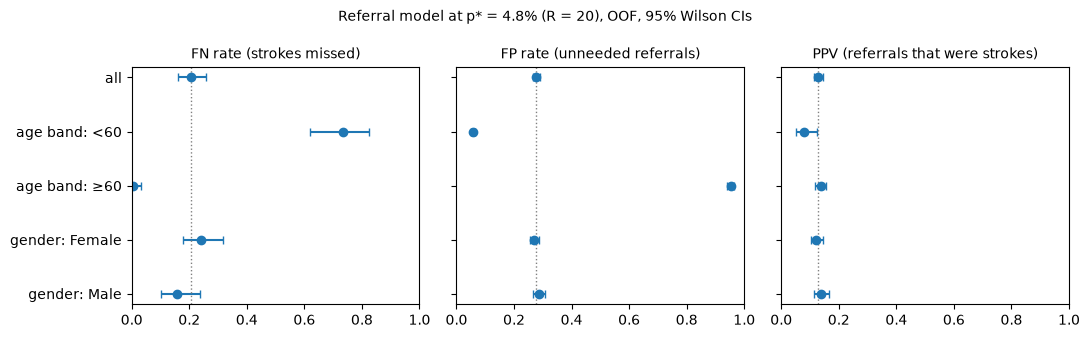

In [6]:
# Dot plot with 95% CIs: one panel per error rate
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
labels = [f"{g}" if g == "all" else f"{gr}: {g}" for gr, g in zip(rates["grouping"], rates["group"])]
yy = np.arange(len(rates))[::-1]
for ax, (m, title) in zip(axes, [("fn_rate", "FN rate (strokes missed)"),
                                  ("fp_rate", "FP rate (unneeded referrals)"),
                                  ("ppv", "PPV (referrals that were strokes)")]):
    est = rates[m].to_numpy()
    err = [est - rates[f"{m}_low"].to_numpy(), rates[f"{m}_high"].to_numpy() - est]
    ax.errorbar(est, yy, xerr=err, fmt="o", capsize=3)
    ax.axvline(est[0], color="grey", ls=":", lw=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1)
axes[0].set_yticks(yy, labels)
fig.suptitle(f"Referral model at p* = {100 * PT:.1f}% (R = {COST_RATIO}), OOF, 95% Wilson CIs", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / "fairness_error_rates.png", bbox_inches="tight")
plt.show()

**Error-rate result (descriptive, no tests, as registered).** At p\* = 4.8% the model refers 1,543 of 5,109 patients (30%). Overall it misses 20.5% of strokes (51 / 249; Wilson 95% CI 15.9% to 25.9%), refers 27.7% of non-stroke patients (26.4% to 29.0%), and 12.8% of referrals are future strokes (11.3% to 14.6%): about 1 in 8.

**Age is where the errors differ, by a lot.**
- **≥ 60:** the model refers almost everyone (1,319 of 1,376, 96%). It misses 1 of 181 strokes (FN rate 0.6%, 0.1% to 3.1%), but 95.3% of non-stroke patients are referred too. PPV 13.7%.
- **< 60:** the model refers few people (224 of 3,733) and misses 50 of 68 strokes (FN rate 73.5%, 62.0% to 82.6%). PPV 8.0%.
- Difference (≥ 60 minus < 60): FN rate −73.0 points (Newcombe 95% CI −82.0 to −61.2); FP rate +89.7 points (88.1 to 91.0); PPV +5.6 points (1.0 to 9.1).

Why: age is the strongest predictor, and almost every patient aged 60+ has a predicted risk above 4.8%, while most younger patients are below it. At R = 20 the model works close to the rule *refer everyone 60+, plus a few younger patients with several risk factors*. This follows from the cost ratio and the base rates, not from a coding error, but it has a cost: **younger patients who will have a stroke are mostly not referred.** The report's ethics section should say so. A lower threshold (higher R) would catch more of them at the cost of many more referrals; that trade-off is Track 5's decision curve.

**Gender: no clear difference.** Men minus women: FN rate −8.4 points (−17.9 to +1.8), FP rate +1.7 (−0.9 to +4.2), PPV +1.5 (−1.9 to +4.9). All CIs include 0, though the FN-rate interval is wide (108 and 141 strokes), so a difference of several points cannot be ruled out.

Tables: `results/tables/fairness_error_rates.csv`, `fairness_error_rate_diffs.csv`. Figure: `results/figures/fairness_error_rates.png`.